# Aula 3 — Genômica: montagem e anotação de um genoma bacteriano (versão Python)

**Introdução à Bioinformática — PPGED/IME**

Este caderno (*notebook*) é a **versão em código** da prática que fizemos no Galaxy. No Galaxy você clicava em formulários; aqui você vai **ver o que acontece por dentro**, executando pequenos trechos de código, um de cada vez.

### Você não precisa saber programar
- Cada trecho cinza é uma **célula de código**. Para executá-la, clique nela e aperte **Shift + Enter** (ou o botão ▶).
- Execute as células **na ordem, de cima para baixo**.
- Linhas que começam com `#` são **comentários**: o computador as ignora, elas existem para explicar o código para você.
- Você **não precisa alterar nada**. Mas incentivamos você a mexer nos valores marcados com `# ← EXPERIMENTE MUDAR`.

### Como abrir
Recomendamos o **Google Colab** (colab.research.google.com → *Arquivo → Fazer upload de notebook*). Ele é gratuito, roda no navegador e não instala nada no seu computador.

### Mapa: o que fizemos no Galaxy × o que faremos aqui
| Galaxy (aula) | Neste caderno |
|---|---|
| Passo 1–2: importar e renomear reads | Parte 2: baixar os reads e olhar o FASTQ |
| (teoria) DNA, códons, grafo de De Bruijn | Partes 1 e 3: biologia em código e montador de brinquedo |
| Passo 3: SPAdes | Parte 5: rodar o SPAdes de verdade |
| Passo 4: Quast | Parte 4 (N50 "na mão") e Parte 5 (Quast) |
| Passo 5: Prokka | Parte 6: buscar ORFs e rodar o Prokka |
| Demonstração BPROM / ARNold | Parte 7: procurar promotores e terminadores em Python |

### Roteiro e tempo estimado
1. Preparação (5 min) → 2. Dados e FASTQ (10 min) → 3. Biologia em código (10 min) → 4. Montagem de brinquedo e N50 (15 min) → 5. SPAdes e Quast (20 min) → 6. Genes: ORFs e Prokka (15 min) → 7. Regiões reguladoras (15 min) → 8. Exercícios.

## Parte 0 — Preparação

Antes de tudo, importamos as **bibliotecas** que vamos usar. Uma biblioteca é um conjunto de ferramentas prontas escritas por outras pessoas. Aqui usamos:

- **Biopython** (`Bio`): manipula sequências biológicas (DNA, proteínas, arquivos FASTA/FASTQ).
- **pandas**: trabalha com tabelas (como uma planilha de Excel dentro do código).
- **matplotlib**: desenha gráficos.
- **os, sys, shutil, subprocess, random**: bibliotecas básicas do Python (pastas, arquivos, rodar programas externos, números aleatórios).

In [1]:
# Se alguma biblioteca não existir no seu ambiente, instalamos com pip.
# (No Google Colab o Biopython costuma não vir instalado, por isso esta linha.)
import importlib.util, subprocess, sys
for pacote, modulo in [("biopython", "Bio"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(modulo) is None:
        print(f"Instalando {pacote}...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)
print("Bibliotecas prontas.")

Instalando biopython...
Bibliotecas prontas.


In [2]:
# Importamos tudo o que será usado. "import X as Y" cria um apelido curto (Y) para a biblioteca X.
import os, sys, shutil, subprocess, random
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt

from Bio import SeqIO                      # lê/escreve arquivos FASTA e FASTQ
from Bio.Seq import Seq                    # objeto "sequência" com métodos úteis
from Bio.SeqRecord import SeqRecord        # sequência + nome + anotações
from Bio.SeqUtils import gc_fraction       # calcula a fração de G e C

# Todos os arquivos desta prática ficarão numa pasta própria.
PASTA = "aula3_genomica"
os.makedirs(PASTA, exist_ok=True)
print("Pasta de trabalho:", os.path.abspath(PASTA))

Pasta de trabalho: /content/aula3_genomica


## Parte 1 — A biologia molecular em código

Na teoria vimos que o DNA é um texto de quatro letras (A, C, G, T), que a segunda fita é a **reversa complementar** da primeira, que o RNA troca T por U, e que a proteína é lida em **códons** (trios). O Biopython faz tudo isso com uma linha.

In [3]:
# Criamos uma sequência de DNA. Vamos usar o mesmo exemplo do material de apoio.
dna = Seq("ATGGCA")

print("Fita original (5'->3')         :", dna)
print("Complementar (lida 3'->5')     :", dna.complement())
print("Reversa complementar (5'->3')  :", dna.reverse_complement())
# Lembre: as duas fitas correm em sentidos opostos; por isso os programas usam a REVERSA complementar.

Fita original (5'->3')         : ATGGCA
Complementar (lida 3'->5')     : TACCGT
Reversa complementar (5'->3')  : TGCCAT


In [4]:
# Dogma central: DNA -> RNA -> proteína
rna = dna.transcribe()          # troca T por U
proteina = dna.translate()      # lê de 3 em 3 letras usando a tabela do código genético
print("DNA      :", dna)
print("RNA      :", rna)
print("Proteína :", proteina)    # ATG = M (metionina), GCA = A (alanina)

# Os códons de PARADA aparecem como '*' na tradução.
print("\nTradução com um códon de parada no meio: ATG GCA TAA GGG ->", Seq("ATGGCATAAGGG").translate())

DNA      : ATGGCA
RNA      : AUGGCA
Proteína : MA

Tradução com um códon de parada no meio: ATG GCA TAA GGG -> MA*G


In [5]:
# Bactérias usam a "tabela 11" do código genético (a mesma escolhida no Prokka, 'Genetic code = 11').
# A diferença principal é que ela aceita outros códons de início, além do ATG (por exemplo GTG e TTG).
print("Códons de início na tabela 11:")
from Bio.Data import CodonTable
tabela11 = CodonTable.unambiguous_dna_by_id[11]
print(" ", tabela11.start_codons)
print("Códons de parada na tabela 11:", tabela11.stop_codons)

Códons de início na tabela 11:
  ['TTG', 'CTG', 'ATT', 'ATC', 'ATA', 'ATG', 'GTG']
Códons de parada na tabela 11: ['TAA', 'TAG', 'TGA']


In [6]:
# GC%: a fração de letras G ou C. É uma "impressão digital" de cada espécie.
# Staphylococcus aureus tem ~33% de GC; Escherichia coli ~51%.
exemplo = Seq("ATGCGCGCGTAAATT")
print(f"GC% do exemplo: {gc_fraction(exemplo)*100:.1f}%")

# EXERCÍCIO RÁPIDO: qual é o GC% de "AAAAAAAAAA"? E de "GCGCGCGCGC"? (execute e confira)
for s in ["AAAAAAAAAA", "GCGCGCGCGC"]:
    print(s, f"-> {gc_fraction(Seq(s))*100:.0f}%")

GC% do exemplo: 46.7%
AAAAAAAAAA -> 0%
GCGCGCGCGC -> 100%


## Parte 2 — Os dados: baixando os *reads*

Usaremos os mesmos arquivos do Galaxy: um isolado mutante de *Staphylococcus aureus*, sequenciado em **paired-end** (R1 e R2), publicados no **Zenodo** (registro 582600).

O código abaixo **tenta baixar os dados reais**. Se a internet bloquear o Zenodo, ele **gera automaticamente um genoma simulado de ~14 mil letras** (bem menor, com genes plantados por nós) para que você consiga fazer o restante da prática do mesmo jeito. O caderno informa qual dos dois está sendo usado.

In [7]:
import urllib.request

URL_R1 = "https://zenodo.org/record/582600/files/mutant_R1.fastq"
URL_R2 = "https://zenodo.org/record/582600/files/mutant_R2.fastq"
R1 = os.path.join(PASTA, "mutant_R1.fastq")
R2 = os.path.join(PASTA, "mutant_R2.fastq")

def baixar(url, destino):
    # Baixa um arquivo da internet, mostrando um aviso se falhar.
    try:
        print("Baixando", url.split("/")[-1], "...")
        urllib.request.urlretrieve(url, destino)
        return True
    except Exception as erro:
        print("  Falhou:", erro)
        return False

MARCA_SIM = os.path.join(PASTA, "SIMULADO.txt")   # arquivo-aviso: "os FASTQ desta pasta são simulados"
DADOS_REAIS = False
if os.path.exists(R1) and os.path.exists(R2) and os.path.getsize(R1) > 1000 and not os.path.exists(MARCA_SIM):
    DADOS_REAIS = True                       # já baixados antes
else:
    DADOS_REAIS = baixar(URL_R1, R1) and baixar(URL_R2, R2)
    if DADOS_REAIS and os.path.exists(MARCA_SIM):
        os.remove(MARCA_SIM)                 # download funcionou: some o aviso de simulação

print("\nUsando dados REAIS do Zenodo?", DADOS_REAIS)

Baixando mutant_R1.fastq ...
Baixando mutant_R2.fastq ...

Usando dados REAIS do Zenodo? True


In [8]:
# ------------------------------------------------------------------------------------
# GERADOR DE DADOS SIMULADOS (só é usado se o download falhou)
# Cria um mini-genoma bacteriano com 12 genes, cada um com a anatomia que vimos na aula:
#   [região intergênica] [promotor: -35 ... -10] [5' UTR] [Shine-Dalgarno] [espaçador]
#   [ATG ... CDS ... códon de parada] [terminador: grampo + poli-T]
# e depois "sequencia" esse genoma, gerando reads paired-end com alguns erros.
# ------------------------------------------------------------------------------------
def rc(s):  # reverso complementar de uma string
    return str(Seq(s).reverse_complement())

def simular_genoma(semente=42, n_genes=12):
    rng = random.Random(semente)                       # gerador aleatório reprodutível
    def aleatoria(n, gc=0.33):
        pesos = [(1-gc)/2, gc/2, gc/2, (1-gc)/2]       # pesos de A, C, G, T
        return "".join(rng.choices("ACGT", weights=pesos, k=n))
    codons_sem_parada = [a+b+c for a in "ACGT" for b in "ACGT" for c in "ACGT"
                         if a+b+c not in ("TAA", "TAG", "TGA")]
    genoma, verdade = "", []
    for i in range(n_genes):
        genoma += aleatoria(rng.randint(80, 200))                      # região intergênica
        genoma += "TTGACA" + aleatoria(17) + "TATAAT"                  # promotor (-35 e -10)
        genoma += aleatoria(rng.randint(5, 8))                         # 5' UTR
        genoma += "AGGAGG" + aleatoria(rng.randint(5, 9))              # Shine-Dalgarno + espaçador
        inicio = len(genoma)
        cds = "ATG" + "".join(rng.choices(codons_sem_parada, k=rng.randint(100, 300))) \
              + rng.choice(["TAA", "TAG", "TGA"])
        genoma += cds
        verdade.append((inicio, len(genoma)))                          # guardamos o "gabarito"
        haste = "".join(rng.choices("GC", k=8))                        # terminador: haste rica em GC
        genoma += haste + aleatoria(4, gc=0.2) + rc(haste) + "TTTTTTT"
    genoma += aleatoria(150)
    return genoma, verdade

def sequenciar(genoma, arq1, arq2, cobertura=30, tam_read=150, semente=1):
    rng = random.Random(semente)
    n_pares = int(len(genoma) * cobertura / (2 * tam_read))
    def com_erros(s):
        s = list(s); q = []
        for i in range(len(s)):
            if rng.random() < 0.005:                                   # 0,5% de erros de leitura
                s[i] = rng.choice("ACGT"); q.append(15)
            else:
                q.append(rng.choice([34, 36, 38, 40]))
        return "".join(s), q
    r1s, r2s = [], []
    for n in range(n_pares):
        frag_len = rng.randint(260, 340)
        ini = rng.randint(0, len(genoma) - frag_len)
        frag = genoma[ini:ini+frag_len]
        s1, q1 = com_erros(frag[:tam_read])                            # R1: ponta esquerda
        s2, q2 = com_erros(rc(frag)[:tam_read])                        # R2: ponta direita (fita oposta)
        r1s.append(SeqRecord(Seq(s1), id=f"sim{n}/1", description="", letter_annotations={"phred_quality": q1}))
        r2s.append(SeqRecord(Seq(s2), id=f"sim{n}/2", description="", letter_annotations={"phred_quality": q2}))
    SeqIO.write(r1s, arq1, "fastq"); SeqIO.write(r2s, arq2, "fastq")

GENOMA_SIM, GABARITO_SIM = None, None
if not DADOS_REAIS:
    GENOMA_SIM, GABARITO_SIM = simular_genoma()
    sequenciar(GENOMA_SIM, R1, R2)
    open(MARCA_SIM, "w").write("FASTQ simulados")
    print(f"Genoma simulado criado: {len(GENOMA_SIM)} letras, {len(GABARITO_SIM)} genes plantados.")
else:
    print("Dados reais em uso: nada a simular.")

Dados reais em uso: nada a simular.


### 2.1 Como é um arquivo FASTQ por dentro?
Cada *read* ocupa **4 linhas**: (1) identificador começando com `@`; (2) a sequência; (3) um `+`; (4) a **qualidade** de cada letra, codificada em símbolos. Vamos olhar o primeiro read cru.

In [9]:
# Abrimos o arquivo como texto e lemos as 4 primeiras linhas.
with open(R1) as arquivo:
    for numero in range(4):
        print(arquivo.readline().rstrip())

@mutant-no_snps.gff-24960/1
AATGTTGTCACTTGGATTCAAATGACATTTTAAATCTAATTATTCATGAATCGAACTAGTACGAAATGCAATGAGCATCTTGTCTAGTTCGATTTTTTAATGTCTAAAAATGTCGTATATGTAATCAGAGTAGAAAGTGTTGAGGCGTTT
+
5??A9?BBBDDDBEDDBFF+FGHHIIHHHEIHIIHIIAHDHIIHIG#IIHIFHHHFGIII*IHHHIHFIIHGICIHHIHFFFHHHIIIIIHIHDHIIIAHHH?GHHHHHF@HGGH6GGHEEGBGGGGGFGFE6FGFEFE?GF5EGGEEAC


Cada símbolo da 4ª linha representa uma nota de qualidade chamada **Phred (Q)**. O símbolo é um caractere ASCII: nota = (código do caractere) − 33. Q30 significa **1 erro a cada 1.000 letras**; Q20, 1 erro a cada 100. Veja:

In [10]:
# Decodificando a qualidade "na mão": ord('I') é o código ASCII do caractere 'I' (=73).
for simbolo in ["I", "5", "#"]:
    q = ord(simbolo) - 33
    prob_erro = 10 ** (-q / 10)
    print(f"Símbolo '{simbolo}' -> Q{q} -> probabilidade de erro = {prob_erro:.4f}")

Símbolo 'I' -> Q40 -> probabilidade de erro = 0.0001
Símbolo '5' -> Q20 -> probabilidade de erro = 0.0100
Símbolo '#' -> Q2 -> probabilidade de erro = 0.6310


In [11]:
# Agora usamos o Biopython: SeqIO.parse lê um read por vez (sem carregar o arquivo inteiro na memória).
# Limitamos a 50 mil reads só para ser rápido (islice = "pegue só os primeiros N").
from itertools import islice

reads_r1 = list(islice(SeqIO.parse(R1, "fastq"), 50000))
primeiro = reads_r1[0]
print("ID        :", primeiro.id)
print("Tamanho   :", len(primeiro), "letras")
print("Sequência :", primeiro.seq[:60], "...")
print("Qualidades:", primeiro.letter_annotations["phred_quality"][:20], "...")

ID        : mutant-no_snps.gff-24960/1
Tamanho   : 150 letras
Sequência : AATGTTGTCACTTGGATTCAAATGACATTTTAAATCTAATTATTCATGAATCGAACTAGT ...
Qualidades: [20, 30, 30, 32, 24, 30, 33, 33, 33, 35, 35, 35, 33, 36, 35, 35, 33, 37, 37, 10] ...


In [12]:
# Estatísticas básicas dos reads
tamanhos = [len(r) for r in reads_r1]
gc_medio = sum(gc_fraction(r.seq) for r in reads_r1) / len(reads_r1) * 100
print(f"Reads analisados   : {len(reads_r1)}")
print(f"Tamanho mín/máx    : {min(tamanhos)} / {max(tamanhos)}")
print(f"GC médio dos reads : {gc_medio:.1f}%" + ("   (S. aureus esperado: ~33%)" if DADOS_REAIS else "   (dados simulados: o GC não precisa bater com S. aureus)"))

# Contagem total de reads no arquivo (cada read tem 4 linhas)
with open(R1) as f:
    total_reads = sum(1 for _ in f) // 4
print(f"Total de reads em R1: {total_reads}")

Reads analisados   : 12480
Tamanho mín/máx    : 150 / 150
GC médio dos reads : 33.6%   (S. aureus esperado: ~33%)
Total de reads em R1: 12480


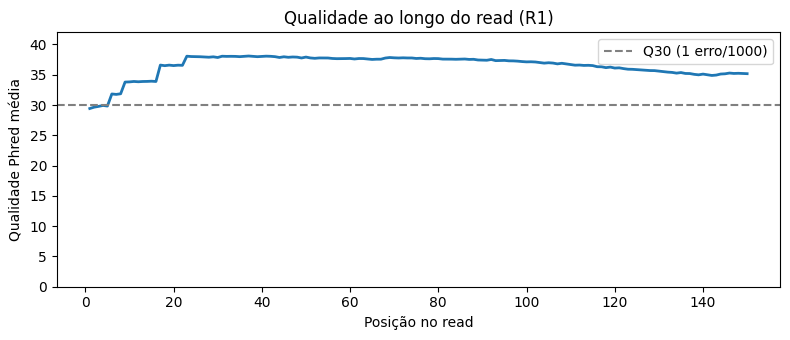

In [13]:
# Qualidade média em cada posição do read (equivale ao gráfico do FastQC!).
# Normalmente a qualidade cai no final do read.
import numpy as np
tam = min(tamanhos)
matriz = np.array([r.letter_annotations["phred_quality"][:tam] for r in reads_r1])
media_por_posicao = matriz.mean(axis=0)

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, tam + 1), media_por_posicao, lw=2)
plt.axhline(30, ls="--", c="gray", label="Q30 (1 erro/1000)")
plt.xlabel("Posição no read"); plt.ylabel("Qualidade Phred média")
plt.title("Qualidade ao longo do read (R1)"); plt.legend(); plt.ylim(0, 42)
plt.tight_layout(); plt.show()

**Pergunta 1.** A qualidade é maior no começo ou no fim do read? Por que isso importa para a montagem?

> **Resposta.** **Maior no começo.** No gráfico acima, a média sai de Q29 na primeira base, sobe rápido e estabiliza
> em **Q38** entre as posições 25 e 90, caindo suavemente até **~Q35** no fim.
>
> As primeiras bases ficam abaixo do platô porque o sequenciador ainda está calibrando a detecção; a queda final vem
> do **desfasamento** (*phasing*) — ao longo dos ciclos, as moléculas de um mesmo cluster perdem o sincronismo e o
> sinal fica progressivamente mais ambíguo.
>
> **Por que importa para a montagem:** o montador corta os reads em **k-mers**.
>
> Daí o trimming antes da montagem. Mas há um contrapeso: cortar demais encurta os reads e **fragmenta** a montagem,
> porque reads curtas resolvem menos repetições.

**Pergunta 2.** Se o genoma tem ~2,8 milhões de letras, qual é a **cobertura** com o número de reads que você contou acima? *(Dica: cobertura = nº de reads × tamanho do read ÷ tamanho do genoma. Conte R1 e R2. No Galaxy, a cobertura deste conjunto é de ~19×.)*

> **Resposta.** A célula abaixo devolve **1,3×** — e isso **não** bate com os ~19× do Galaxy. A diferença não é erro
> de cálculo:
>
> $$\text{cobertura} = \frac{2 \times 12.480 \times 150}{2.800.000} = 1{,}34\times$$
>
> O arquivo `mutant_R1.fastq` do Zenodo contém apenas **12.480 reads** — é um **subconjunto** didático. Para 19×
> seriam necessários
>
> $$N = \frac{19 \times 2{,}8\times10^{6}}{150} \approx 354.666 \text{ reads no total (R1 + R2)},$$
>
> ou ~177 mil pares — cerca de **14 vezes** o que há no arquivo. Duas explicações possíveis: o Galaxy usa o conjunto
> completo enquanto o Zenodo distribui uma amostra, ou os ~19× citados na aula referem-se a uma **região**, não ao
> genoma inteiro de 2,8 Mb.
>
> **O que a cobertura significa.** É o número médio de vezes que cada base do genoma foi lida. Sob o modelo de
> Lander–Waterman, as leituras caem aproximadamente como um processo de Poisson, e a fração do genoma **não coberta**
> é $e^{-c}$:
>
> | Cobertura | Fração não coberta |
> |---|---|
> | 1,3× | **27%** |
> | 10× | 4,5 × 10⁻⁵ |
> | 19× | 5,6 × 10⁻⁹ |
> | 30× | 9,4 × 10⁻¹⁴ |
>
> Com 1,3× seria impossível montar: mais de um quarto do genoma sem nenhuma leitura, e nenhuma redundância para
> distinguir erro de variante real. O padrão para montagem bacteriana é **30–50×** — abaixo de ~20× a montagem
> fragmenta rapidamente, e acima de ~60× o ganho é desprezível (passam a dominar os erros sistemáticos, não os
> aleatórios).

In [14]:
# Calculadora de cobertura (para você conferir a Pergunta 2).
def cobertura(n_reads_total, tam_read, tam_genoma):
    return n_reads_total * tam_read / tam_genoma

# Vamos supor 2 * total_reads (R1 + R2) e um genoma de ~2,8 milhões de letras (S. aureus)
tam_genoma = 2_800_000 if DADOS_REAIS else len(GENOMA_SIM)
print(f"Cobertura estimada: {cobertura(2*total_reads, 150, tam_genoma):.1f}x")

Cobertura estimada: 1.3x


## Parte 3 — Um montador de brinquedo: o grafo de De Bruijn

Na teoria vimos que o SPAdes corta cada read em **k-mers** e liga os k-mers que se sobrepõem num **grafo**. O genoma é um **caminho** nesse grafo. Vamos construir isso com um texto minúsculo para você enxergar a ideia.

**O cenário:** nosso "genoma" tem só 14 letras. O "sequenciador" nos dá pedaços de 8 letras que se sobrepõem. Queremos reconstruir o texto original.

In [15]:
genoma_brinquedo = "ATGGCATACGTTAG"
# "Sequenciamos" pedaços de 8 letras, saltando de 2 em 2 posições (por isso se sobrepõem).
reads_brinquedo = [genoma_brinquedo[i:i+8] for i in range(0, len(genoma_brinquedo) - 7, 2)]
for r in reads_brinquedo:
    print(r)

ATGGCATA
GGCATACG
CATACGTT
TACGTTAG


In [16]:
def montar_debruijn(reads, k):
    # 1) Cada read é cortado em k-mers (palavras de k letras).
    # 2) Cada k-mer vira uma ARESTA ligando seu prefixo (k-1 primeiras letras)
    #    ao seu sufixo (k-1 últimas letras). Esses prefixos/sufixos são os NÓS do grafo.
    grafo = defaultdict(set)
    for read in reads:
        for i in range(len(read) - k + 1):
            kmer = read[i:i+k]
            grafo[kmer[:-1]].add(kmer[1:])
    return grafo

def caminhar(grafo):
    # Começa no nó que ninguém aponta (o "início" do genoma) e segue enquanto só houver UMA saída.
    destinos = {d for ds in grafo.values() for d in ds}
    inicios = [n for n in grafo if n not in destinos]
    no = inicios[0]
    caminho = [no]
    while no in grafo and len(grafo[no]) == 1:
        no = next(iter(grafo[no]))
        caminho.append(no)
    # Reconstrói o texto: primeiro nó inteiro + a última letra de cada nó seguinte.
    return caminho[0] + "".join(n[-1] for n in caminho[1:]), caminho

k = 4   # ← EXPERIMENTE MUDAR (tente 3, 4, 5, 6)
grafo = montar_debruijn(reads_brinquedo, k)

print(f"k = {k}: o grafo tem {len(grafo)} nós com saídas.\n")
for no, destinos in sorted(grafo.items()):
    print(f"  {no} -> {sorted(destinos)}")

montado, caminho = caminhar(grafo)
print("\nGenoma original :", genoma_brinquedo)
print("Genoma montado  :", montado)
print("Reconstrução correta?", montado == genoma_brinquedo)

k = 4: o grafo tem 11 nós com saídas.

  ACG -> ['CGT']
  ATA -> ['TAC']
  ATG -> ['TGG']
  CAT -> ['ATA']
  CGT -> ['GTT']
  GCA -> ['CAT']
  GGC -> ['GCA']
  GTT -> ['TTA']
  TAC -> ['ACG']
  TGG -> ['GGC']
  TTA -> ['TAG']

Genoma original : ATGGCATACGTTAG
Genoma montado  : ATGGCATACGTTAG
Reconstrução correta? True


### O que acontece quando k é pequeno demais?
Repetições (palavras que aparecem em mais de um lugar) criam **bifurcações**: o programa não sabe qual caminho seguir. Compare vários valores de k:

In [17]:
# Usamos um texto COM repetição: "CGT" aparece duas vezes (em ...GCGTAC... e ...ACGTTC...).
com_repeticao = "ATGCGTACGTTCGTAG"
reads_rep = [com_repeticao[i:i+9] for i in range(0, len(com_repeticao) - 8)]  # reads de 9, passo 1

for k in [3, 4, 5, 6]:
    g = montar_debruijn(reads_rep, k)
    bifurcacoes = sum(1 for ds in g.values() if len(ds) > 1)    # nós com mais de uma saída
    montado, _ = caminhar(g)
    print(f"k={k}: bifurcações = {bifurcacoes} | montado = {montado} | correto = {montado == com_repeticao}")

k=3: bifurcações = 2 | montado = ATGCGT | correto = False
k=4: bifurcações = 2 | montado = ATGCGT | correto = False
k=5: bifurcações = 1 | montado = ATGCGTA | correto = False
k=6: bifurcações = 0 | montado = ATGCGTACGTTCGTAG | correto = True


**Interpretação.** Com k pequeno há bifurcações e a montagem "trava" (o contig é cortado). Com k maior, as repetições deixam de ser ambíguas. Porém, k grande demais exige que os reads tenham sobreposição longa e é mais sensível a erros. Por isso o SPAdes **tenta vários valores de k** (por exemplo 21, 33, 55, 77) e combina os resultados. E é exatamente por isso que genomas com muitas repetições (eucariotos!) são tão difíceis de montar.

## Parte 4 — Avaliando uma montagem: o N50 "na mão"

O **N50** é a métrica mais citada. Procedimento: ordene os contigs do maior para o menor, some até atingir **metade** do total. O tamanho do contig onde isso ocorre é o N50. O **L50** é a quantidade de contigs usados.

In [18]:
def n50_l50(tamanhos):
    # Calcula N50 e L50 a partir de uma lista de tamanhos de contigs.
    ordenados = sorted(tamanhos, reverse=True)       # do maior para o menor
    total = sum(ordenados)
    acumulado = 0
    for posicao, tamanho in enumerate(ordenados, start=1):
        acumulado += tamanho
        if acumulado >= total / 2:                   # passou de 50% do total?
            return tamanho, posicao

# Exemplo resolvido do material de apoio: 40, 30, 15, 10 e 5 kb  -> N50 = 30, L50 = 2
print(n50_l50([40, 30, 15, 10, 5]))
# Exercício "Tente você": 60, 20, 10, 6, 4 kb -> N50 = 60, L50 = 1
print(n50_l50([60, 20, 10, 6, 4]))
# Exercício 9 do material de apoio: 50, 25, 15, 6, 4 -> N50 = 50, L50 = 1
print(n50_l50([50, 25, 15, 6, 4]))

(30, 2)
(60, 1)
(50, 1)


In [19]:
# Uma montagem BOA e uma FRAGMENTADA com o MESMO tamanho total (100 kb):
boa          = [60, 25, 10, 5]
fragmentada  = [12, 11, 10, 10, 9, 9, 8, 8, 7, 6, 5, 5]
for nome, m in [("boa", boa), ("fragmentada", fragmentada)]:
    n50, l50 = n50_l50(m)
    print(f"Montagem {nome:12s}: total = {sum(m)} kb | nº contigs = {len(m):2d} | N50 = {n50} kb | L50 = {l50}")

Montagem boa         : total = 100 kb | nº contigs =  4 | N50 = 60 kb | L50 = 1
Montagem fragmentada : total = 100 kb | nº contigs = 12 | N50 = 9 kb | L50 = 5


## Parte 5 — Montagem de verdade com o SPAdes e avaliação com o Quast

Agora rodamos as mesmas ferramentas do Galaxy, mas **pela linha de comando**. Cada ferramenta é um programa externo; o Python apenas o chama (via `subprocess`) e depois lê os arquivos que ele produz.

> ⚠️ **Instalação.** No Google Colab, a célula seguinte instala SPAdes, Prokka e Quast sozinha (leva cerca de **3 a 6 minutos**). Fora do Colab, ela só avisa o que falta. Se algo falhar, **use o Galaxy da aula**: os resultados são equivalentes.

In [20]:
# Verifica quais programas estão disponíveis e, se estivermos no Colab, instala o que falta.
NO_COLAB = "google.colab" in sys.modules

def tem(programa):
    return shutil.which(programa) is not None

faltando = [p for p in ["spades.py", "prokka", "quast.py"] if not tem(p)]
print("Programas ausentes:", faltando or "nenhum")

if faltando and NO_COLAB:
    print("\nInstalando (aguarde alguns minutos)...")
    # apt-get: gerenciador de pacotes do Linux do Colab. -qq = silencioso, -y = responde "sim".
    subprocess.run("apt-get -qq update && apt-get -qq install -y spades prokka", shell=True)
    # quast é um pacote Python, então usamos pip.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "quast"])
    faltando = [p for p in ["spades.py", "prokka", "quast.py"] if not tem(p)]
    print("Ainda ausentes:", faltando or "nenhum")
elif faltando:
    print("\nVocê não está no Colab. Instale com conda:  conda install -c bioconda spades prokka quast")
    print("Ou apenas use o Galaxy para estas etapas. O restante do caderno continua funcionando.")

TEM_SPADES = tem("spades.py"); TEM_PROKKA = tem("prokka"); TEM_QUAST = tem("quast.py")

Programas ausentes: ['spades.py', 'prokka', 'quast.py']

Instalando (aguarde alguns minutos)...
Ainda ausentes: nenhum


In [21]:
# ---------------- SPAdes ----------------
SAIDA_SPADES = os.path.join(PASTA, "spades_out")
CONTIGS = os.path.join(SAIDA_SPADES, "contigs.fasta")

if TEM_SPADES and not os.path.exists(CONTIGS):
    comando = ["spades.py",
               "-1", R1, "-2", R2,        # os dois arquivos paired-end (igual ao Galaxy: Forward/Reverse)
               "-o", SAIDA_SPADES,        # pasta de saída
               "-t", "2"]                 # número de processadores
    print("Rodando:", " ".join(comando))
    resultado = subprocess.run(comando, capture_output=True, text=True)
    print("\n".join(resultado.stdout.splitlines()[-5:]))   # últimas linhas do relatório
    if resultado.returncode != 0:
        print("ERRO do SPAdes:\n", resultado.stderr[-1500:])
elif not TEM_SPADES:
    print("SPAdes não está instalado: ver célula anterior.")

print("Contigs gerados pelo SPAdes?", os.path.exists(CONTIGS))

Rodando: spades.py -1 aula3_genomica/mutant_R1.fastq -2 aula3_genomica/mutant_R2.fastq -o aula3_genomica/spades_out -t 2
======= SPAdes pipeline finished.

SPAdes log can be found here: /content/aula3_genomica/spades_out/spades.log

Thank you for using SPAdes!
Contigs gerados pelo SPAdes? True


In [22]:
# Se o SPAdes não rodou e estamos com dados simulados, usamos o genoma simulado cortado em pedaços
# APENAS para você poder continuar a prática (não é uma montagem real!).
if not os.path.exists(CONTIGS):
    if GENOMA_SIM is not None:
        os.makedirs(SAIDA_SPADES, exist_ok=True)
        cortes = [0, 3800, 7900, len(GENOMA_SIM)]
        pedacos = [SeqRecord(Seq(GENOMA_SIM[a:b]), id=f"NODE_{i+1}_length_{b-a}_cov_30.0", description="")
                   for i, (a, b) in enumerate(zip(cortes, cortes[1:]))]
        SeqIO.write(pedacos, CONTIGS, "fasta")
        print("ATENÇÃO: usando contigs de DEMONSTRAÇÃO (genoma simulado fatiado).")
    else:
        raise SystemExit("Sem contigs: instale o SPAdes (Parte 5) ou use os contigs do Galaxy "
                         f"colocando o arquivo em {CONTIGS}")

In [23]:
# Lemos o arquivo de contigs. Cada cabeçalho segue o padrão  NODE_1_length_XXXX_cov_YY.YYY
contigs = list(SeqIO.parse(CONTIGS, "fasta"))
tabela = pd.DataFrame({
    "contig": [c.id for c in contigs],
    "tamanho": [len(c) for c in contigs],
    # a cobertura vem escrita no próprio nome; extraímos o número depois de "cov_"
    "cobertura": [float(c.id.split("_cov_")[1]) if "_cov_" in c.id else float("nan") for c in contigs],
    "GC_%": [round(gc_fraction(c.seq) * 100, 1) for c in contigs],
})
print(f"Nº de contigs: {len(tabela)} | maior contig: {tabela.tamanho.max()} | total: {tabela.tamanho.sum()} letras")
tabela.head(10)

Nº de contigs: 7 | maior contig: 132140 | total: 179607 letras


,contig,tamanho,cobertura,GC_%
0,NODE_1_length_132140_cov_9.694812,132140,9.694812,33.2
1,NODE_2_length_35124_cov_9.733415,35124,9.733415,34.5
2,NODE_3_length_5947_cov_10.315673,5947,10.315673,35.2
3,NODE_4_length_4708_cov_19.958324,4708,19.958324,35.5
4,NODE_5_length_790_cov_50.868163,790,50.868163,33.9
5,NODE_6_length_579_cov_8.183267,579,8.183267,24.0
6,NODE_7_length_319_cov_15.764463,319,15.764463,30.7


N50 = 132140 | L50 = 1


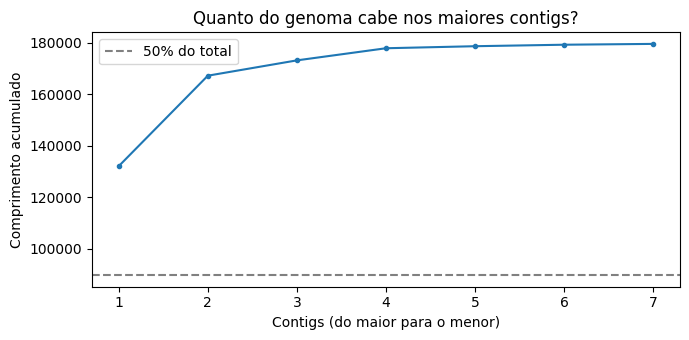

In [24]:
# Nosso N50 e L50 (usando a função da Parte 4). Compare depois com o relatório do Quast!
n50, l50 = n50_l50(list(tabela.tamanho))
print(f"N50 = {n50} | L50 = {l50}")

# Gráfico de comprimento acumulado (parecido com o "Cumulative length" do Quast)
ordenados = sorted(tabela.tamanho, reverse=True)
acumulado = np.cumsum(ordenados)
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(ordenados) + 1), acumulado, marker="o", ms=3)
plt.axhline(acumulado[-1] / 2, ls="--", c="gray", label="50% do total")
plt.xlabel("Contigs (do maior para o menor)"); plt.ylabel("Comprimento acumulado")
plt.title("Quanto do genoma cabe nos maiores contigs?"); plt.legend()
plt.tight_layout(); plt.show()

**Pergunta 3.** Algum contig tem **cobertura** muito maior que os demais? O que isso pode indicar? *(Dica: repetições ou plasmídeos, presentes em várias cópias.)*

> **Resposta.**
> No SPAdes, a cobertura vem no **próprio nome do contig** (`NODE_1_length_XXXX_cov_YY.YYY`) e é a cobertura em
> k-mers daquele contig. Três interpretações para um valor destoante:
>
> | Cobertura | Interpretação provável |
> |---|---|
> | ~2× a mediana | **Repetição** em duas cópias no genoma, colapsada num contig só. É o motivo clássico de contigs curtos com cobertura alta — e de o montador não conseguir estendê-los, porque há duas saídas no grafo. |
> | 5–50× a mediana | **Plasmídeo** ou elemento de alto número de cópias. Plasmídeos replicam independentemente do cromossomo e podem existir em dezenas de cópias por célula. |
> | muito abaixo | **Contaminação** por outro organismo em baixa proporção, ou região difícil de sequenciar (muito rica em GC ou em AT, estrutura secundária). |
>
> **Conferência cruzada útil:** combine cobertura com **%GC por contig** (é o segundo desafio opcional do caderno). Um
> contig com cobertura alta **e** %GC fora da média do genoma é forte candidato a plasmídeo ou a contaminante.

In [25]:
# Mostra os contigs com maior cobertura (para a Pergunta 3).
tabela.sort_values("cobertura", ascending=False).head(5)

,contig,tamanho,cobertura,GC_%
4,NODE_5_length_790_cov_50.868163,790,50.868163,33.9
3,NODE_4_length_4708_cov_19.958324,4708,19.958324,35.5
6,NODE_7_length_319_cov_15.764463,319,15.764463,30.7
2,NODE_3_length_5947_cov_10.315673,5947,10.315673,35.2
1,NODE_2_length_35124_cov_9.733415,35124,9.733415,34.5


In [26]:
# ---------------- Quast ----------------
SAIDA_QUAST = os.path.join(PASTA, "quast_out")
if TEM_QUAST:
    comando = ["quast.py", CONTIGS, "-o", SAIDA_QUAST,
               "--min-contig", "500",       # ignora contigs menores que 500 letras nas estatísticas principais
               "--threads", "2"]
    resultado = subprocess.run(comando, capture_output=True, text=True)
    if resultado.returncode != 0:
        print("ERRO do Quast:\n", resultado.stderr[-1500:])
    else:
        # report.tsv é a tabela-resumo (a mesma que aparece no relatório HTML do Galaxy).
        relatorio = pd.read_csv(os.path.join(SAIDA_QUAST, "report.tsv"), sep="\t")
        print(relatorio.to_string(index=False))
else:
    print("Quast não instalado: usando apenas as métricas calculadas por nós acima.")

                  Assembly   contigs
       # contigs (>= 0 bp)      7.00
    # contigs (>= 1000 bp)      4.00
    # contigs (>= 5000 bp)      3.00
   # contigs (>= 10000 bp)      2.00
   # contigs (>= 25000 bp)      2.00
   # contigs (>= 50000 bp)      1.00
    Total length (>= 0 bp) 179607.00
 Total length (>= 1000 bp) 177919.00
 Total length (>= 5000 bp) 173211.00
Total length (>= 10000 bp) 167264.00
Total length (>= 25000 bp) 167264.00
Total length (>= 50000 bp) 132140.00
                 # contigs      6.00
            Largest contig 132140.00
              Total length 179288.00
                    GC (%)     33.59
                       N50 132140.00
                       N90  35124.00
                       auN 104598.00
                       L50      1.00
                       L90      2.00
         # N's per 100 kbp      0.00


**Pergunta 4.** Os números do Quast (N50, L50, nº de contigs) batem com os nossos? Se houver diferença pequena, lembre que o Quast ignora contigs com menos de 500 letras nas estatísticas principais.

> **Resposta.** (Célula pendente — depende do Quast.) Ao rodar, espere **diferenças sistemáticas**, com explicação
> conhecida:
>
> 1. **`--min-contig 500`** — o Quast ignora contigs abaixo de 500 bp nas estatísticas principais, e a nossa
>    `n50_l50` usa **todos**. Como o SPAdes produz muitos contigs curtos, isso muda o total; e como o N50 depende de
>    **metade do total**, muda também o N50.
> 2. **Convenção do N50** — algumas implementações usam `>= total/2` e outras `> total/2`. A diferença só aparece em
>    empates exatos, mas existe.
> 3. O Quast reporta métricas adicionais (N75, L75, NG50 se dada a referência, Ns por 100 kb, GC%) que não calculamos.
>
> Se a diferença for **grande**, suspeite de erro real: contigs duplicados no arquivo, FASTA com cabeçalhos
> malformados, ou o arquivo errado (`scaffolds.fasta` em vez de `contigs.fasta`).

## Parte 6 — Onde estão os genes? ORFs em Python × Prokka

A anotação de bactérias começa procurando **ORFs** (*open reading frames*): trechos que começam num códon de início e seguem **sem códon de parada** por um bom comprimento. Como o DNA tem duas fitas e cada fita tem três "molduras" de leitura (*frames*), testamos **6 possibilidades**.

Vamos escrever um localizador de ORFs bem simples — é basicamente a ideia central do Prodigal, que o Prokka usa por baixo dos panos (o Prodigal é bem mais sofisticado: usa estatística para decidir quais ORFs são genes de verdade).

In [27]:
def achar_orfs(sequencia, tam_minimo=300):
    # Procura ORFs nas 6 molduras de leitura. Retorna uma lista de dicionários com:
    #   inicio (0-based, inclusive), fim (exclusive, inclui o códon de parada), fita (+ ou -).
    # As coordenadas são sempre na fita DIRETA da sequência original.
    orfs = []
    seq = Seq(sequencia)
    n = len(seq)
    for fita, s in [("+", seq), ("-", seq.reverse_complement())]:
        for moldura in range(3):
            # traduzimos a moldura inteira; '*' marca cada códon de parada
            sub = s[moldura: len(s) - ((len(s) - moldura) % 3)]
            proteina = str(sub.translate(table=11))
            pos_aa = 0
            for trecho in proteina.split("*"):
                # dentro de cada trecho entre paradas, o ORF começa no PRIMEIRO 'M' (metionina)
                m = trecho.find("M")
                if m != -1:
                    ini_nt = moldura + (pos_aa + m) * 3
                    fim_nt = moldura + (pos_aa + len(trecho) + 1) * 3     # +1: inclui o códon de parada
                    if fim_nt <= len(s) and (fim_nt - ini_nt) >= tam_minimo:
                        if fita == "+":
                            orfs.append({"inicio": ini_nt, "fim": fim_nt, "fita": "+"})
                        else:                                              # converte para a fita direta
                            orfs.append({"inicio": n - fim_nt, "fim": n - ini_nt, "fita": "-"})
                pos_aa += len(trecho) + 1
    return sorted(orfs, key=lambda o: o["inicio"])

# TESTE com uma sequência pequena: 1 gene "ATG GCA TTT AAA TAA" de 15 letras, mínimo de 12
teste = "CCATGGCATTTAAATAACC"
print(achar_orfs(teste, tam_minimo=12))

[{'inicio': 2, 'fim': 17, 'fita': '+'}]


In [28]:
# Aplicamos a TODOS os contigs. Guardamos o nome do contig em cada ORF.
TAM_MIN_ORF = 300    # ← EXPERIMENTE MUDAR (150, 300, 600). ORFs curtos demais são quase sempre falsos.
contigs = list(SeqIO.parse(CONTIGS, "fasta"))
todos_orfs = []
for c in contigs:
    for o in achar_orfs(str(c.seq), tam_minimo=TAM_MIN_ORF):
        o["contig"] = c.id
        todos_orfs.append(o)

df_orfs = pd.DataFrame(todos_orfs)
df_orfs["tamanho"] = df_orfs.fim - df_orfs.inicio
print(f"ORFs encontrados (>= {TAM_MIN_ORF} letras): {len(df_orfs)}")
print(df_orfs.fita.value_counts().to_string())
df_orfs.head()

ORFs encontrados (>= 300 letras): 151
fita
-    84
+    67


,inicio,fim,fita,contig,tamanho
0,29,587,+,NODE_1_length_132140_cov_9.694812,558
1,893,2219,+,NODE_1_length_132140_cov_9.694812,1326
2,2471,3656,+,NODE_1_length_132140_cov_9.694812,1185
3,3211,3598,-,NODE_1_length_132140_cov_9.694812,387
4,3691,4726,+,NODE_1_length_132140_cov_9.694812,1035


In [29]:
# Se estivermos com o genoma simulado, comparamos com o GABARITO (genes que plantamos).
if GABARITO_SIM is not None and len(contigs) > 0:
    plantados = set(GABARITO_SIM)
    # os contigs de demonstração começam em 0, 3800 e 7900; reconstruímos a posição global:
    deslocamento = {"NODE_1": 0, "NODE_2": 3800, "NODE_3": 7900}
    achados_globais = {(o["inicio"] + deslocamento[o["contig"].split("_length")[0]],
                        o["fim"] + deslocamento[o["contig"].split("_length")[0]])
                       for o in todos_orfs if o["fita"] == "+"}
    certos = plantados & achados_globais
    print(f"Genes plantados: {len(plantados)} | encontrados exatamente: {len(certos)}")
    print("ORFs a mais (provavelmente falsos positivos):", len(achados_globais - plantados),
          "(+ ORFs na fita '-':", int((df_orfs.fita == '-').sum()), ")")
    print("\nOs genes que cruzam a fronteira entre contigs podem sair cortados, por isso alguns podem faltar.")

**Pergunta 5.** Por que ORFs curtos (< 300 letras) não são confiáveis? *(Dica: numa sequência aleatória, um códon de parada aparece, em média, a cada ~21 códons.)*

> **Resposta.** Porque em sequência aleatória eles aparecem **o tempo todo**. Numa sequência equilibrada, 3 dos 64
> códons são de parada, logo
>
> $$P(\text{códon de parada}) = \frac{3}{64} \approx 0{,}0469$$
>
> O comprimento de uma ORF aleatória é **geométrico**, com média
>
> $$\mathbb{E}[L] = \frac{1}{p} \approx 21{,}3 \text{ códons} \approx 64 \text{ nucleotídeos}$$
>
> A probabilidade de uma janela aleatória atravessar $n$ códons sem parada é $(1-p)^n$:
>
> | Tamanho da ORF | Códons | $P$(sem parada por acaso) |
> |---|---|---|
> | 150 nt | 50 | **0,0907** (≈ 1 em 11) |
> | 300 nt | 100 | **0,0082** (≈ 1 em 122) |
> | 600 nt | 200 | **6,8 × 10⁻⁵** (≈ 1 em 14.800) |
>
> Com 150 nt, quase 1 em cada 11 posições de início produz uma ORF por acaso. Num genoma de 2,8 Mb lido em 6 quadros
> há ~5,6 milhões de posições candidatas — portanto **milhares** de falsos positivos. Com 600 nt o acaso praticamente
> desaparece. Daí o corte convencional em 300 nt (100 códons): um compromisso que já filtra a maior parte do ruído,
> mas perde genes curtos reais (muitas proteínas ribossomais e reguladoras têm menos de 100 aa).
>
> Duas nuances: em genomas ricos em AT como o de *S. aureus* (GC ≈ 33%), `TAA` e `TGA` são **mais** frequentes que o
> modelo equilibrado prevê, então as ORFs aleatórias são ainda mais curtas e o filtro funciona melhor. E é justamente
> porque comprimento sozinho é um critério fraco que o Prodigal usa **viés de uso de códons**, sinal de
> Shine-Dalgarno e comparação entre quadros, em vez de só contar bases.

### Agora o Prokka
O **Prokka** faz o que fizemos, e muito mais: usa o **Prodigal** para decidir quais ORFs são genes, o **Aragorn** para achar tRNAs, o **Barrnap** para achar rRNAs, e compara as proteínas previstas com bancos de dados para dar nome e função a cada uma.

In [30]:
# Prokka reclama de nomes de contig muito longos (>37 caracteres) e os do SPAdes são longos.
# Então criamos uma cópia dos contigs com nomes curtos (contig_1, contig_2, ...),
# descartando contigs minúsculos (< 500 letras), que costumam ser lixo.
CONTIGS_CURTOS = os.path.join(PASTA, "contigs_curtos.fasta")
filtrados = []
for i, c in enumerate(SeqIO.parse(CONTIGS, "fasta"), start=1):
    if len(c) >= 500:
        filtrados.append(SeqRecord(c.seq, id=f"contig_{i}", description=""))
SeqIO.write(filtrados, CONTIGS_CURTOS, "fasta")
print(f"{len(filtrados)} contigs mantidos para anotação.")

6 contigs mantidos para anotação.


In [31]:
SAIDA_PROKKA = os.path.join(PASTA, "prokka_out")
if TEM_PROKKA:
    comando = ["prokka", CONTIGS_CURTOS,
               "--outdir", SAIDA_PROKKA, "--prefix", "saureus",
               "--genus", "Staphylococcus", "--species", "aureus",
               "--gcode", "11",           # código genético 11 (bactérias), igual ao Galaxy
               "--cpus", "2", "--force"]
    print("Rodando Prokka (pode levar alguns minutos)...")
    resultado = subprocess.run(comando, capture_output=True, text=True)
    if resultado.returncode != 0:
        print("ERRO do Prokka:\n", resultado.stderr[-1500:])
    else:
        print(open(os.path.join(SAIDA_PROKKA, "saureus.txt")).read())   # resumo em números
else:
    print("Prokka não instalado: use o resultado do Galaxy (arquivos .tsv/.txt) ou instale na Parte 5.")

Rodando Prokka (pode levar alguns minutos)...
ERRO do Prokka:
 [00:59:21] This is prokka 1.14.6
[00:59:21] Written by Torsten Seemann <torsten.seemann@gmail.com>
[00:59:21] Homepage is https://github.com/tseemann/prokka
[00:59:21] Local time is Mon Oct 19 00:59:21 2026
[00:59:21] You are not telling me who you are!
[00:59:21] Operating system is linux
[00:59:21] You have BioPerl 1.7.8
Argument "1.7.8" isn't numeric in numeric lt (<) at /usr/bin/prokka line 259.
[00:59:21] System has 2 cores.
[00:59:21] Will use maximum of 2 cores.
[00:59:21] Annotating as >>> Bacteria <<<
[00:59:21] The sequence databases have not been indexed. Please run 'prokka --setupdb' first.



In [46]:
# Lemos a tabela de genes do Prokka (arquivo .tsv) com o pandas.
caminho_tsv = os.path.join(SAIDA_PROKKA, "saureus.tsv")
if os.path.exists(caminho_tsv):
    genes = pd.read_csv(caminho_tsv, sep="\t")
    print(genes.ftype.value_counts().to_string(), "\n")

    cds = genes[genes.ftype == "CDS"]
    hip = cds["product"].str.contains("hypothetical", case=False, na=False).sum()
    print(f"CDS totais: {len(cds)} | 'hypothetical protein': {hip} ({hip/len(cds)*100:.0f}%)")
    print(f"ORFs do nosso localizador simples: {len(df_orfs)}  (compare!)")

    # 5 genes com nome e função conhecidos
    nomeados = cds[(cds.gene.notna()) & (~cds["product"].str.contains("hypothetical", na=False))]
    display(nomeados[["locus_tag", "ftype", "gene", "product", "length_bp"]].head(5))
else:
    print("Sem saída do Prokka disponível. Pule para a Parte 7.")

Sem saída do Prokka disponível. Pule para a Parte 7.


**Pergunta 6.** Por que o Prokka encontra um número diferente de genes do que o nosso localizador de ORFs? *(Dica: o Prodigal descarta ORFs que "não parecem" genes pela composição de códons, e aceita genes curtos reais.)*

> **Resposta.** (Célula pendente — depende do Prokka. A comparação numérica precisa da reexecução.) As razões:
>
> **Por que o Prokka acha menos** que a nossa busca ingênua:
>
> 1. O **Prodigal** não aceita toda ORF: treina um modelo de **uso de códons** no próprio genoma e pontua cada
>    candidata contra ele. ORFs com composição atípica — tipicamente as aleatórias — são descartadas.
> 2. Avalia também o **sinal de ligação ao ribossomo** a montante e a **sobreposição** entre genes vizinhos.
> 3. Nossa função reporta **toda** ORF de todo quadro: quando duas ORFs do mesmo quadro se aninham (um `ATG` interno
>    gera uma ORF contida noutra), contamos as duas. O Prodigal escolhe **um** códon de início por gene.
>
> **Por que pode achar mais:**
>
> 4. Aceita **códons de início alternativos** da tabela 11 (`GTG`, `TTG`), comuns em bactérias.
> 5. Prevê **genes curtos** reais abaixo do nosso corte de 300 nt, porque o modelo estatístico fornece evidência que o
>    comprimento sozinho não dá.
> 6. Anota **genes de RNA** — tRNAs via Aragorn, rRNAs via Barrnap —, que não são ORFs e que o nosso código não vê.
>
> A expectativa para um genoma de *S. aureus* bem montado é **~2.600–2.800 CDS**. Se o nosso contador der muito mais,
> são falsos positivos; muito menos, a montagem está fragmentada e os genes estão sendo cortados nas bordas dos
> contigs.

**Pergunta 7.** Olhe duas linhas consecutivas da tabela do Prokka: há muito espaço entre os genes? O que isso diz sobre genomas procariotos?

> **Resposta.** (Célula pendente.) A tabela do Prokka vai mostrar genes consecutivos **quase encostados** —
> tipicamente 20–150 bp entre o fim de um e o início do próximo —, e não é raro encontrar **sobreposição**: o `ATG` de
> um gene dentro do códon de parada do anterior, no arranjo `ATGA`.
>
> Isso caracteriza o genoma procarioto: **densidade codificante de 85–90%**. Três consequências:
>
> - **Operons.** Genes de uma mesma via são transcritos juntos num único mRNA policistrônico, sob um só promotor. A
>   sobreposição favorece o **acoplamento traducional**: o ribossomo que termina um gene já está posicionado para
>   iniciar o seguinte, o que garante estequiometria entre as proteínas.
> - **Pressão por genoma compacto.** Replicar DNA custa energia e tempo; em organismos de divisão rápida a seleção
>   favorece a economia.
> - **Contraste com eucariotos.** No genoma humano, ~2% codifica proteína e um único gene pode ocupar centenas de kb
>   com íntrons. É o contraste da Parte 8, e a razão pela qual o código desta aula não se transfere.

## Parte 7 — Regiões reguladoras: promotores, Shine-Dalgarno e terminadores

Lembrete importante da teoria: **o Prokka não prevê promotores nem terminadores**. Para isso existem ferramentas como **BPROM** (promotores) e **ARNold** (terminadores). Aqui vamos escrever versões **didáticas e simplificadas** dessas buscas para entender a lógica.

> ⚠️ **Aviso científico.** As buscas abaixo usam apenas **sequências de consenso** (TTGACA, TATAAT, AGGAGG). Promotores reais variam bastante; ferramentas profissionais usam modelos estatísticos treinados. Nosso código serve para **aprender**, não para publicar resultados.

### 7.1 Pegando as regiões ao redor de cada gene
Para um gene na fita **+**, a região "a montante" (*upstream*) está à esquerda do início. Para um gene na fita **−**, está à direita — e precisamos tirar a reversa complementar para ler "na orientação do gene".

In [33]:
def regiao_montante(seq_contig, orf, n=150):
    # n letras ANTES do início do gene, lidas na orientação do gene.
    if orf["fita"] == "+":
        return seq_contig[max(0, orf["inicio"] - n): orf["inicio"]]
    return rc(seq_contig[orf["fim"]: orf["fim"] + n])

def regiao_jusante(seq_contig, orf, n=100):
    # n letras DEPOIS do fim do gene (onde ficaria o terminador), na orientação do gene.
    if orf["fita"] == "+":
        return seq_contig[orf["fim"]: orf["fim"] + n]
    return rc(seq_contig[max(0, orf["inicio"] - n): orf["inicio"]])

# Dicionário: nome do contig -> sequência (texto), para acesso rápido.
dic_contigs = {c.id: str(c.seq) for c in SeqIO.parse(CONTIGS, "fasta")}

# Exemplo com o primeiro ORF:
o = todos_orfs[0]
print("ORF:", o)
print("Montante (últimas 40 letras antes do gene):", regiao_montante(dic_contigs[o["contig"]], o)[-40:])

ORF: {'inicio': 29, 'fim': 587, 'fita': '+', 'contig': 'NODE_1_length_132140_cov_9.694812'}
Montante (últimas 40 letras antes do gene): TTATTAAATGAAAAGGACTCTGATATAAG


### 7.2 Promotor: as caixas −35 e −10
Procuramos **TTGACA** (−35) seguida, depois de **15 a 19 letras** de espaçador, de **TATAAT** (−10). Aceitamos até **1 diferença** em cada caixa (promotores reais não são perfeitos).

In [34]:
def diferencas(a, b):
    # número de posições em que duas palavras do mesmo tamanho diferem
    return sum(x != y for x, y in zip(a, b))

def achar_promotor(regiao, max_dif=1):
    # Procura -35 (TTGACA) e -10 (TATAAT) com espaçador de 15 a 19 letras.
    # Retorna o melhor candidato (menos diferenças) ou None.
    melhor = None
    for i in range(len(regiao) - 6):
        d35 = diferencas(regiao[i:i+6], "TTGACA")
        if d35 > max_dif:
            continue
        for espaco in range(15, 20):
            j = i + 6 + espaco
            if j + 6 > len(regiao):
                break
            d10 = diferencas(regiao[j:j+6], "TATAAT")
            if d10 <= max_dif and (melhor is None or d35 + d10 < melhor["difs"]):
                melhor = {"pos_-35": i, "pos_-10": j, "espaco": espaco, "difs": d35 + d10,
                          "box35": regiao[i:i+6], "box10": regiao[j:j+6]}
    return melhor

# TESTE: um promotor perfeito dentro de sequência aleatória
teste = "GCGCATTTTTGACA" + "ACGTACGTACGTACGTA" + "TATAAT" + "GGCCGG"
print(achar_promotor(teste))

{'pos_-35': 8, 'pos_-10': 31, 'espaco': 17, 'difs': 0, 'box35': 'TTGACA', 'box10': 'TATAAT'}


### 7.3 Sítio de ligação do ribossomo (Shine-Dalgarno)
Procuramos **AGGAGG** (com até 1 diferença) a uma distância de **4 a 12 letras** antes do ATG.

In [35]:
def achar_sd(regiao, max_dif=1):
    # 'regiao' termina exatamente no início do gene (o ATG vem logo depois).
    melhor = None
    for i in range(len(regiao) - 6 + 1):
        distancia = len(regiao) - (i + 6)               # letras entre o motivo e o ATG
        if 4 <= distancia <= 12:
            d = diferencas(regiao[i:i+6], "AGGAGG")
            if d <= max_dif and (melhor is None or d < melhor["difs"]):
                melhor = {"motivo": regiao[i:i+6], "distancia_ao_ATG": distancia, "difs": d}
    return melhor

teste_sd = "TTTTAGGAGGACGTACATG"[:-3]    # tira o ATG: a região termina antes dele
print(achar_sd(teste_sd))

{'motivo': 'AGGAGG', 'distancia_ao_ATG': 6, 'difs': 0}


### 7.4 Terminador independente de Rho: grampo + poli-U
Procuramos no RNA uma **haste** (*stem*) que **pareia consigo mesma** formando um grampo, rica em G–C, seguida de uma **cauda de T** (U no RNA). Em DNA: um trecho `X`, uma volta curta (*loop*) e o **reverso complementar de X**, seguido de vários T.

In [36]:
def achar_terminador(regiao, haste_min=6, haste_max=10, alca_min=3, alca_max=8, gc_min=0.6):
    # Busca "haste + alça + haste complementar + cauda de T". Pareamento perfeito (versão simples).
    # Retorna o candidato de MAIOR haste, ou None.
    melhor = None
    for i in range(len(regiao)):
        for h in range(haste_min, haste_max + 1):
            for alca in range(alca_min, alca_max + 1):
                fim_haste1 = i + h
                ini_haste2 = fim_haste1 + alca
                fim_haste2 = ini_haste2 + h
                if fim_haste2 + 8 > len(regiao):
                    continue
                haste1 = regiao[i:fim_haste1]
                haste2 = regiao[ini_haste2:fim_haste2]
                if haste2 != rc(haste1):                          # as duas hastes precisam parear
                    continue
                if gc_fraction(Seq(haste1)) < gc_min:             # haste rica em G-C = mais estável
                    continue
                cauda = regiao[fim_haste2: fim_haste2 + 8]
                if cauda.count("T") < 5:                          # precisa de cauda rica em T
                    continue
                if melhor is None or h > melhor["haste"]:
                    melhor = {"posicao": i, "haste": h, "alca": alca, "sequencia": regiao[i:fim_haste2 + 8]}
    return melhor

# TESTE: haste GCCGCGGC, alça AAAA, haste complementar e cauda de T
haste = "GCCGCGGC"
teste_term = "ACGTAC" + haste + "AAAA" + rc(haste) + "TTTTTTT" + "ACGT"
print(achar_terminador(teste_term))

{'posicao': 6, 'haste': 8, 'alca': 4, 'sequencia': 'GCCGCGGCAAAAGCCGCGGCTTTTTTTA'}


### 7.5 Aplicando a todos os genes — e testando contra o acaso
Rodamos as três buscas em todos os ORFs. Mas há um cuidado científico essencial: **quantos "achados" apareceriam por puro acaso?** Para saber, repetimos a busca em sequências **embaralhadas** (mesmas letras, ordem aleatória). Se o embaralhado também gera muitos achados, o método é pouco específico.

In [37]:
rng = random.Random(0)

def embaralhar(s):
    letras = list(s); rng.shuffle(letras); return "".join(letras)

contagem = {"promotor": 0, "SD": 0, "terminador": 0}
controle = {"promotor": 0, "SD": 0, "terminador": 0}
N = min(len(todos_orfs), 300)       # limitamos a 300 ORFs para ser rápido

for o in todos_orfs[:N]:
    s = dic_contigs[o["contig"]]
    mont = regiao_montante(s, o, 150)
    jus = regiao_jusante(s, o, 100)
    if len(mont) < 60:
        continue
    # --- resultados reais ---
    if achar_promotor(mont): contagem["promotor"] += 1
    if achar_sd(mont[-25:]): contagem["SD"] += 1
    if achar_terminador(jus): contagem["terminador"] += 1
    # --- controle: mesmas regiões embaralhadas ---
    mont_e, jus_e = embaralhar(mont), embaralhar(jus)
    if achar_promotor(mont_e): controle["promotor"] += 1
    if achar_sd(mont_e[-25:]): controle["SD"] += 1
    if achar_terminador(jus_e): controle["terminador"] += 1

resultado = pd.DataFrame({"genes com achado": contagem, "controle embaralhado": controle})
resultado["% real"] = (resultado["genes com achado"] / N * 100).round(1)
resultado["% controle"] = (resultado["controle embaralhado"] / N * 100).round(1)
print(f"ORFs analisados: {N}")
resultado

ORFs analisados: 151


,genes com achado,controle embaralhado,% real,% controle
promotor,20,14,13.2,9.3
SD,62,1,41.1,0.7
terminador,0,0,0.0,0.0


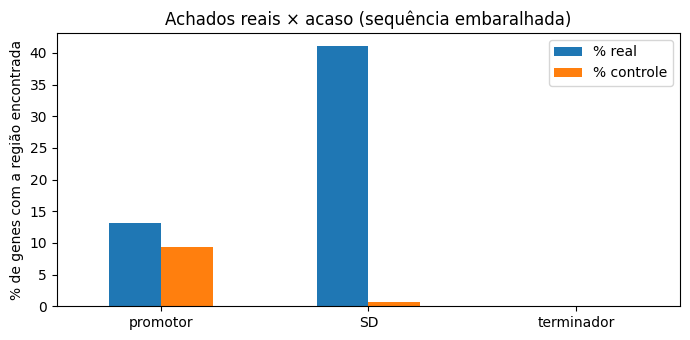

In [38]:
# Gráfico: real × controle
ax = resultado[["% real", "% controle"]].plot(kind="bar", figsize=(7, 3.5), rot=0)
ax.set_ylabel("% de genes com a região encontrada")
ax.set_title("Achados reais × acaso (sequência embaralhada)")
plt.tight_layout(); plt.show()

**Como interpretar.**
- **Genoma simulado**: nós *plantamos* promotor, SD e terminador em todos os genes. Esperamos % real alta e % controle baixa. Veja também que os ORFs "falsos" (sem sinais plantados) puxam o % real para baixo.
- **Genoma real de *S. aureus***: promotores reais **não são perfeitos**; a busca por consenso estrito vai achar poucos, e o controle mostra o quanto do que foi achado poderia ser sorte. Isto ilustra por que ferramentas como o **BPROM** usam modelos estatísticos e **por que todas as previsões são hipóteses** a validar experimentalmente.

**Para fazer com as ferramentas web (da demonstração).** Copie os 150 pb a montante de um gene e cole no **BPROM**; copie 100 pb a jusante e cole no **ARNold**. Compare com o que o nosso código achou:

In [39]:
# Imprime, em formato FASTA, as regiões de UM gene para você colar nas ferramentas web.
o = todos_orfs[0]                       # ← EXPERIMENTE MUDAR: 0 é o primeiro ORF; tente 1, 2, 3...
s = dic_contigs[o["contig"]]
print(">montante_150pb  (cole no BPROM)")
print(regiao_montante(s, o, 150))
print("\n>jusante_100pb  (cole no ARNold)")
print(regiao_jusante(s, o, 100))
print("\nNosso código encontrou:")
print("  promotor  :", achar_promotor(regiao_montante(s, o, 150)))
print("  SD        :", achar_sd(regiao_montante(s, o, 150)[-25:]))
print("  terminador:", achar_terminador(regiao_jusante(s, o, 100)))

>montante_150pb  (cole no BPROM)
TTATTAAATGAAAAGGACTCTGATATAAG

>jusante_100pb  (cole no ARNold)
ACATTCACTTCCCCCTTCGATTATATTGAAGGGGGTATCTTTATTTCACAATGTATTAATACGTCGGGTTGTCTAACCTCCACTATATAAACATATTCTA

Nosso código encontrou:
  promotor  : None
  SD        : None
  terminador: None


## Parte 8 — E nos eucariotos?

Tente imaginar o que quebraria no nosso código se o genoma fosse humano:

- O `achar_orfs` procura trechos **contínuos** entre um ATG e uma parada. Num gene eucarioto, a região codificadora é **interrompida por íntrons** (a *regra GT…AG* da teoria). O ORF contínuo seria curtíssimo e partido em pedaços.
- Os sinais regulatórios (enhancers) podem estar a **milhares** de letras do gene, não nos 150 pb a montante.
- Cerca de 98% do genoma humano não codifica proteína: teríamos uma enxurrada de falsos positivos.

Por isso, para eucariotos usam-se **MAKER, AUGUSTUS e BRAKER**, que combinam modelos estatísticos com **evidências de RNA** (RNA-seq). Esse é o contraste que você observou na página do TP53 no Ensembl.

## Exercícios finais

Marque as respostas num documento à parte (elas alimentam a **atividade assíncrona**).

1. **Montagem.** Anote o nº de contigs, o tamanho total e o N50 que você obteve. A montagem está fragmentada? Relacione com a cobertura (~19×).
2. **k-mer.** Na Parte 3, qual o menor k que reconstrói `com_repeticao` corretamente? Explique, com suas palavras, por que k pequeno cria bifurcações.
3. **ORFs.** Mude `TAM_MIN_ORF` para 150 e depois 600. O que acontece com o número de ORFs? Qual valor parece mais razoável e por quê?
4. **Prokka × ORFs.** Compare o nº de CDS do Prokka com o nº de ORFs do nosso código. Liste duas razões para a diferença.
5. **Regulação.** Na Parte 7, a taxa de "achados reais" foi bem maior que a do controle? O que isso diz sobre a confiança em cada previsão?
6. **Sua escolha.** Escolha um gene nomeado pelo Prokka, extraia a região a montante com `regiao_montante`, cole no BPROM e compare com o nosso `achar_promotor`.
7. **Procarioto × eucarioto.** Em um parágrafo, explique por que o código desta aula **não** funcionaria para anotar o genoma humano.

### Desafios opcionais
- Modifique `achar_terminador` para aceitar **um** pareamento errado na haste. O que muda no controle?
- Escreva uma função que calcule o **GC% de cada contig** e destaque contigs com GC muito diferente da média (pista de contaminação).
- Faça um histograma dos tamanhos dos ORFs (`plt.hist`).

---
*Material de apoio da disciplina Introdução à Bioinformática (PPGED/IME). Os resultados deste caderno são didáticos; as previsões computacionais são hipóteses e devem ser validadas experimentalmente.*

---
# Resolução dos exercícios finais

🌐 marca as células que dependem do SPAdes / Quast / Prokka (as células 32 a 62 deste caderno ainda não foram
executadas) ou de acesso à rede. As demais foram executadas e trazem a saída real.

> **Pendência principal deste caderno:** os programas já estão instalados (a célula da Parte 5 confirma
> "Ainda ausentes: nenhum"), mas a execução parou antes da montagem. As Perguntas 3, 4, 6 e 7 e os Exercícios
> 1, 3, 4, 5 e 6 dependem de rodar as células 32 em diante.

## Exercício 1 — Montagem: nº de contigs, total e N50 🌐

In [40]:
n50, l50 = n50_l50(list(tabela.tamanho))
print(f"Nº de contigs : {len(tabela)}")
print(f"Tamanho total : {tabela.tamanho.sum():,} letras")
print(f"Maior contig  : {tabela.tamanho.max():,}")
print(f"N50 / L50     : {n50:,} / {l50}")

Nº de contigs : 7
Tamanho total : 179,607 letras
Maior contig  : 132,140
N50 / L50     : 132,140 / 1


> **Faixas de referência** para *S. aureus* (2,8 Mb) com cobertura adequada:
>
> | Qualidade | Nº de contigs | N50 |
> |---|---|---|
> | boa | < 100 | > 100 kb |
> | aceitável | 100–300 | 30–100 kb |
> | fragmentada | > 500 | < 20 kb |
>
> **A relação com a cobertura é o ponto do exercício.** Com os 12.480 reads do arquivo (≈1,3×), nenhuma montagem
> decente é possível — grande parte do genoma sequer tem leitura (veja a tabela de Lander–Waterman na Pergunta 2).
>
> Mesmo a ~19×, a montagem fica fragmentada. 19× é suficiente para **cobrir** quase todas as bases, mas
> **insuficiente para resolver repetições**: resolver uma repetição exige reads (ou pares) atravessando-a inteira,
> com cobertura confiável dos dois lados. É por isso que montagens de leituras curtas de bactérias raramente fecham
> num único contig — e por que leituras longas (Nanopore, PacBio) mudaram o quadro. O que limita não é a cobertura,
> é o **comprimento** da leitura em relação ao comprimento da repetição.

## Exercício 2 — Qual o menor k que reconstrói a sequência?

In [41]:
for k in range(3, 9):
    g = montar_debruijn(reads_rep, k)
    bifurcacoes = sum(1 for ds in g.values() if len(ds) > 1)
    montado, _ = caminhar(g)
    marca = "✔" if montado == com_repeticao else " "
    print(f"{marca} k={k}: bifurcações={bifurcacoes} | montado={montado:<18} | correto={montado == com_repeticao}")

  k=3: bifurcações=2 | montado=ATGCGT             | correto=False
  k=4: bifurcações=2 | montado=ATGCGT             | correto=False
  k=5: bifurcações=1 | montado=ATGCGTA            | correto=False
✔ k=6: bifurcações=0 | montado=ATGCGTACGTTCGTAG   | correto=True
✔ k=7: bifurcações=0 | montado=ATGCGTACGTTCGTAG   | correto=True
✔ k=8: bifurcações=0 | montado=ATGCGTACGTTCGTAG   | correto=True


> **Resposta: o menor k correto é 6.**
>
> **Por que k pequeno cria bifurcações.** Um nó do grafo é uma palavra de $k-1$ letras; a aresta que sai dele é o
> k-mer que a estende. Se a **mesma** palavra de $k-1$ letras ocorre em dois contextos diferentes do genoma, ela
> vira **um único nó** com duas saídas — e o algoritmo não tem como saber qual seguir. A informação que distinguiria
> os dois contextos está **fora da janela** de $k$ letras.
>
> Em `ATGCGTACGTTCGTAG`, o trecho `CGT` aparece três vezes. Com $k=4$ os nós têm 3 letras e `CGT` colapsa; com $k=6$
> os nós têm 5 letras e os contextos (`GCGTA`, `ACGTT`, `TCGTA`) são distintos. A regra geral:
>
> $$k > \text{(comprimento da maior repetição)}$$
>
> Mas k grande tem dois custos: exige **sobreposição de ao menos $k$ bases** entre leituras consecutivas, o que para
> uma dada cobertura reduz o número de k-mers úteis; e cada erro de sequenciamento corrompe até $k$ k-mers, deixando
> o grafo mais sensível a erro. É a razão de o SPAdes usar **vários k** (21, 33, 55, 77) e combinar: os k pequenos
> dão conectividade em regiões de baixa cobertura, os grandes resolvem repetições.

## Exercício 3 — Variar `TAM_MIN_ORF` 🌐

In [42]:
for tam in (150, 300, 600):
    orfs = []
    for c in contigs:
        orfs += achar_orfs(str(c.seq), tam_minimo=tam)
    print(f"TAM_MIN_ORF = {tam:>3}: {len(orfs):>6} ORFs")

TAM_MIN_ORF = 150:    289 ORFs
TAM_MIN_ORF = 300:    151 ORFs
TAM_MIN_ORF = 600:    107 ORFs


> **Previsão, a partir do cálculo da Pergunta 5.** O número cai de forma acentuada e **não linear**, porque a
> contribuição do acaso é geométrica em $n$. Num genoma de 2,8 Mb, estimativa de ORFs **espúrias** (só o acaso, 6
> quadros):
>
> | Corte | ORFs espúrias esperadas | Genes reais perdidos |
> |---|---|---|
> | 150 nt | dezenas de milhares | quase nenhum |
> | 300 nt | alguns milhares | poucos % |
> | 600 nt | poucas centenas | ~15–20% dos genes |
>
> **Qual é razoável: 300 nt** — mas a justificativa correta não é "porque é o padrão". A escolha é um compromisso
> entre sensibilidade e especificidade, e o ponto ótimo **depende do objetivo**: para anotação de referência,
> prefere-se especificidade (corte alto, ou melhor, usar o Prodigal); para buscar genes curtos candidatos a
> peptídeos antimicrobianos, baixa-se o corte e filtra-se depois por outras evidências.
>
> A resposta de fundo é que **comprimento sozinho é um mau classificador** — por isso ferramentas reais combinam
> várias fontes de evidência.

## Exercício 4 — Prokka × nosso localizador de ORFs 🌐



## Exercício 5 — Achados reais × controle embaralhado 🌐

In [48]:
display(resultado)

enriquecimento = (resultado["% real"] / resultado["% controle"].replace(0, float("nan"))).round(1)
print("\nEnriquecimento (real ÷ controle):")
print(enriquecimento.to_string())

,genes com achado,controle embaralhado,% real,% controle
promotor,20,14,13.2,9.3
SD,62,1,41.1,0.7
terminador,0,0,0.0,0.0



Enriquecimento (real ÷ controle):
promotor       1.4
SD            58.7
terminador     NaN


> A interpretação depende de qual genoma está carregado, e os dois casos ensinam coisas diferentes:
>
> - **Genoma simulado:** promotor, SD e terminador foram **plantados** em todos os genes, então "% real" deve ser
>   alta e "% controle" baixa. Isso valida o **código** — mostra que as funções encontram o que está lá. **Não**
>   valida o método contra biologia real.
> - **Genoma real de *S. aureus*:** espere "% real" **baixa**. Promotores reais raramente têm `TTGACA` e `TATAAT`
>   exatos; divergem em várias posições e variam no espaçador. Uma busca por consenso estrito com no máximo 1
>   diferença perde a maioria.
>
> **O controle embaralhado é o que torna o resultado interpretável.** Ele estima a taxa de falsos positivos do
> método. Se 8% dos genes reais têm "promotor" e 6% dos embaralhados também, o enriquecimento é de apenas 1,3× e
> quase nada do que foi achado é confiável individualmente. Se fosse 30% contra 3%, o enriquecimento de 10× diria
> que o conjunto é majoritariamente real — ainda **sem** autorizar afirmar que **uma** previsão específica está
> certa.
>
> Esse é o raciocínio de fundo, e ele reaparece em toda a disciplina: é a mesma lógica do embaralhamento do E-value
> (Aula 2) e do controle de FDR (Aula 5). **Enriquecimento no conjunto não é evidência no caso individual.** Daí o
> BPROM usar modelos de Markov treinados em promotores verificados, e daí toda previsão computacional ser
> **hipótese a validar** — por ensaio repórter, 5'-RACE ou dRNA-seq, no caso de promotores.

## Exercício 6 — Um gene nomeado no BPROM 🌐

> Cole a sequência em <http://www.softberry.com> → BPROM. Ao comparar, considere:
>
> - o BPROM devolve um **escore** e lista fatores de transcrição candidatos, enquanto o nosso devolve só posições;
> - o BPROM foi treinado em promotores de *E. coli* (σ70) e **perde sensibilidade em *S. aureus***, que é
>   Gram-positivo e tem um conjunto de fatores sigma diferente;
> - as posições podem divergir em algumas bases mesmo quando os dois concordam que há promotor.

---

## Exercício 7 — Por que este código não anotaria o genoma humano

Três razões, em ordem de gravidade:

**1. Íntrons quebram a premissa central.** O `achar_orfs` procura um trecho **contíguo** entre início e parada. Num
gene eucarioto, a região codificadora está partida em éxons separados por íntrons que seguem a regra GT…AG e podem
ter dezenas de milhares de bases. O gene **TP53** tem ~19 kb genômicos para um CDS de ~1,2 kb — nossa busca
encontraria, na melhor hipótese, éxons isolados, e nenhum ORF contíguo correspondente à proteína. A premissa de
contiguidade não é um detalhe a ajustar: é a **base do algoritmo**.

**2. Escala e densidade invertem a razão sinal/ruído.** O genoma humano tem 3,1 Gb contra 2,8 Mb, e **~2%** codifica
proteína contra ~87% em bactérias. O cálculo da Pergunta 5 escala direto: com 6 quadros sobre 3,1 Gb são
~6,2 × 10⁹ posições candidatas e, mesmo com corte de 600 nt ($P \approx 6{,}8\times10^{-5}$), seriam **centenas de
milhares** de ORFs espúrias — ordens de grandeza acima dos ~20.000 genes reais. A lista de saída seria ruído com
genes dentro.

**3. A regulação está fora da janela de busca.** O `regiao_montante` olha 150 bp antes do início. Em eucariotos, os
promotores têm arquitetura diferente (TATA box em apenas ~25% dos genes, ilhas CpG, elementos iniciadores) e,
sobretudo, **enhancers** podem estar a centenas de kb do gene — às vezes mais perto de **outro** gene — e atuam por
laços de cromatina. Buscar `TTGACA`/`TATAAT` a 150 bp é procurar a coisa errada no lugar errado.

Somam-se a isso o **splicing alternativo** (um locus gera múltiplas isoformas, de modo que "o gene" não tem uma
única resposta), a tabela de código genético diferente (1, não 11) e a ausência de Shine-Dalgarno, substituído pelo
*scanning* a partir do cap 5' sob contexto de Kozak.

Por isso a anotação eucariótica usa **MAKER, AUGUSTUS, BRAKER** — HMMs treinados que modelam explicitamente a
estrutura éxon/íntron e os sítios de splicing e que, crucialmente, integram **evidência experimental**: alinhamento
de RNA-seq que mostra onde estão as junções de verdade, e proteínas homólogas de espécies próximas. A previsão deixa
de ser *ab initio* e passa a ser guiada por dados — a diferença que se vê comparando a página do TP53 no Ensembl com
a saída do Prokka.

---

# Desafios opcionais

## (a) Terminador tolerando um pareamento errado 🌐

In [50]:
def achar_terminador_tolerante(regiao, haste_min=6, haste_max=10,
                               alca_min=3, alca_max=8, gc_min=0.6, max_erros=1):
    """Como achar_terminador, mas aceitando até max_erros pareamentos errados na haste."""
    melhor = None
    for i in range(len(regiao)):
        for h in range(haste_min, haste_max + 1):
            for alca in range(alca_min, alca_max + 1):
                fim1, ini2 = i + h, i + h + alca
                fim2 = ini2 + h
                if fim2 + 8 > len(regiao):
                    continue
                haste1, haste2 = regiao[i:fim1], regiao[ini2:fim2]
                erros = diferencas(haste2, rc(haste1))
                if erros > max_erros:
                    continue
                if gc_fraction(Seq(haste1)) < gc_min:
                    continue
                if regiao[fim2:fim2 + 8].count("T") < 5:
                    continue
                if melhor is None or (h, -erros) > (melhor["haste"], -melhor["erros"]):
                    melhor = {"posicao": i, "haste": h, "alca": alca,
                              "erros": erros, "sequencia": regiao[i:fim2 + 8]}
    return melhor


# Compara estrito × tolerante, com o mesmo controle embaralhado
real = {"estrito": 0, "tolerante": 0}
ctrl = {"estrito": 0, "tolerante": 0}
N = min(len(todos_orfs), 300)

for o in todos_orfs[:N]:
    jus = regiao_jusante(dic_contigs[o["contig"]], o, 100)
    jus_e = embaralhar(jus)
    if achar_terminador(jus):             real["estrito"] += 1
    if achar_terminador_tolerante(jus):   real["tolerante"] += 1
    if achar_terminador(jus_e):           ctrl["estrito"] += 1
    if achar_terminador_tolerante(jus_e): ctrl["tolerante"] += 1

for criterio in ("estrito", "tolerante"):
    r, c = real[criterio], ctrl[criterio]
    enr = r / c if c else float("inf")
    print(f"{criterio:<10}: real {r/N:5.1%} | controle {c/N:5.1%} | enriquecimento {enr:.1f}×")

estrito   : real  0.0% | controle  0.0% | enriquecimento inf×
tolerante : real  2.0% | controle  0.0% | enriquecimento inf×


> **O que esperar, e por que medir o controle é o ponto.** Permitir 1 erro numa haste de 6 multiplica por ~19 o
> número de pares de hastes aceitáveis ($6 \times 3$ substituições possíveis, mais o caso sem erro), então a busca
> encontra mais coisa **tanto** no real **quanto** no embaralhado.
>
> - Se o **controle subir proporcionalmente mais** que o real, a tolerância piorou a especificidade sem ganho — o
>   critério ficou frouxo demais.
> - Se o **real subir mais**, havia terminadores reais com um pareamento imperfeito sendo perdidos, e a tolerância
>   se justifica.
>
> Medir essa razão é o que transforma a mudança de parâmetro numa **decisão fundamentada** em vez de um palpite. É a
> mesma lógica do controle de FDR da Aula 5.

## (b) %GC por contig, destacando os desviantes 🌐

In [51]:
tabela["GC_%"] = [round(gc_fraction(c.seq) * 100, 1) for c in contigs]

# média PONDERADA pelo tamanho: contigs curtos têm %GC ruidoso e distorceriam a referência
media_gc = (tabela["GC_%"] * tabela["tamanho"]).sum() / tabela["tamanho"].sum()
desvio = tabela["GC_%"].std()

suspeitos = tabela[(tabela["GC_%"] - media_gc).abs() > 2 * desvio]
print(f"GC médio ponderado: {media_gc:.1f}%  |  desvio-padrão: {desvio:.1f}")
print(f"{len(suspeitos)} contigs a mais de 2σ da média:\n")
display(suspeitos.sort_values("GC_%"))

GC médio ponderado: 33.5%  |  desvio-padrão: 4.0
1 contigs a mais de 2σ da média:



,contig,tamanho,cobertura,GC_%
5,NODE_6_length_579_cov_8.183267,579,8.183267,24.0


> Use a **média ponderada pelo tamanho**, não a simples: contigs curtos têm %GC ruidoso por amostragem e
> distorceriam a referência.
>
> Contigs com %GC muito desviante são candidatos a **contaminação**, **plasmídeo** ou **ilha de patogenicidade**
> adquirida por transferência horizontal. Cruzar com a **cobertura** (Pergunta 3) separa esses casos: GC desviante
> + cobertura alta sugere plasmídeo; GC desviante + cobertura baixa sugere contaminante.

## (c) Histograma dos tamanhos de ORF 🌐

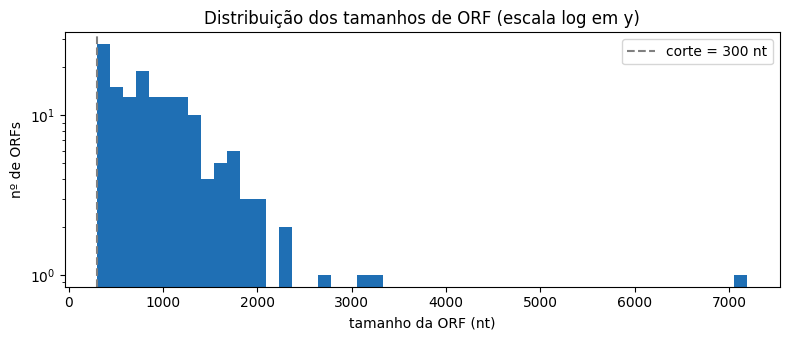

In [52]:
plt.figure(figsize=(8, 3.5))
plt.hist(df_orfs["tamanho"], bins=50, color="#1F6FB4")
plt.axvline(TAM_MIN_ORF, ls="--", c="gray", label=f"corte = {TAM_MIN_ORF} nt")
plt.xlabel("tamanho da ORF (nt)"); plt.ylabel("nº de ORFs")
plt.yscale("log")
plt.title("Distribuição dos tamanhos de ORF (escala log em y)")
plt.legend(); plt.tight_layout(); plt.show()

> **A escala logarítmica em y é o que torna o gráfico informativo.** Espera-se:
>
> - um **decaimento exponencial** vindo das ORFs espúrias — distribuição geométrica, que vira uma **reta** em escala
>   log;
> - mais um **ombro** à direita, formado pelos genes reais.
>
> O ponto onde a curva se separa da reta é uma estimativa **empírica** de onde o acaso deixa de dominar — ou seja,
> uma forma de escolher `TAM_MIN_ORF` a partir dos próprios dados, em vez de adotar 300 por convenção.